# **Installations**

In [2]:
!apt-get update
!apt-get install -y libopencv-dev

Get:1 https://cloud.r-project.org/bin/linux/ubuntu jammy-cran40/ InRelease [3,626 B]
Get:2 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2204/x86_64  InRelease [1,581 B]
Get:3 http://security.ubuntu.com/ubuntu jammy-security InRelease [129 kB]
Get:4 https://r2u.stat.illinois.edu/ubuntu jammy InRelease [6,555 B]
Get:5 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2204/x86_64  Packages [1,199 kB]
Hit:6 http://archive.ubuntu.com/ubuntu jammy InRelease
Get:7 https://cloud.r-project.org/bin/linux/ubuntu jammy-cran40/ Packages [61.9 kB]
Get:8 http://archive.ubuntu.com/ubuntu jammy-updates InRelease [128 kB]
Hit:9 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu jammy InRelease
Get:10 https://r2u.stat.illinois.edu/ubuntu jammy/main amd64 Packages [2,631 kB]
Hit:11 https://ppa.launchpadcontent.net/graphics-drivers/ppa/ubuntu jammy InRelease
Hit:12 https://ppa.launchpadcontent.net/ubuntugis/ppa/ubuntu jammy InRelease
Get:13 http://archive.ubuntu.com/ubunt

In [ ]:
!pip install nvcc4jupyter
%load_ext nvcc4jupyter

In [ ]:
!nvidia-smi

# **checking the image size**

In [18]:
import cv2

# Read the image
image_path = 'FlowerHighResolution.jpg'  # Replace with the path to your image
image = cv2.imread(image_path)

# Get the size of the image
height, width, channels = image.shape

# Print the size
print(f"The image size is: {width}x{height}")

The image size is: 3872x2592


# **the sequential code**

In [31]:
%%writefile sequential.c
#include <stdio.h>
#include <opencv2/opencv.hpp>
#include <chrono>
using namespace cv;

void prewittFilter(const unsigned char* input, unsigned char* output, int Gx[3][3] , int Gy[3][3] , int width , int height , int f) {

  for(int x=0 ; x<width ; x++ )
  {
        for(int y=0 ; y<height ; y++ )
    {
      if (x >= 1 && x < width - 1 && y >= 1 && y < height - 1) {
          int GxSum = 0;
          int GySum = 0;

          for (int i = -1; i <= 1; i++) {
              for (int j = -1; j <= 1; j++) {
                  int pixel = input[(y + i) * width + (x + j)];
                  GxSum += pixel * Gx[i + f/2][j + f/2];
                  GxSum += pixel * Gy[(i + f/2)][j + f/2];
              }
          }

          int magnitude = sqrtf(GxSum * GxSum + GySum * GySum);
          magnitude = (magnitude>255)*255 + (magnitude<=255)*magnitude;

          output[y * width + x] = (unsigned char)magnitude;
      }
    }
  }

}

int main() {
    int f =3;

    //preparing the kernels/masks
    int Gx[3][3] = {
    {-1, 0, 1},
    {-1, 0, 1},
    {-1, 0, 1}
};
    int Gy[3][3] = {
    {-1, -1, -1},
    {0, 0, 0},
    {1, 1, 1}
};

    Mat inputImage = imread("Flower.jpg", IMREAD_GRAYSCALE);
    if (inputImage.empty()) {
        fprintf(stderr, "Error: Could not open input image\\n");
        return -1;
    }

    int width = inputImage.cols;
    int height = inputImage.rows;

    size_t imageSize = width * height * sizeof(unsigned char);
    unsigned char* output = (unsigned char*)malloc(imageSize);

    auto start = std::chrono::high_resolution_clock::now();

    prewittFilter(inputImage.data, output, Gx ,  Gy , width ,  height , f);

    auto end = std::chrono::high_resolution_clock::now();
    std::chrono::duration<double> elapsed = end - start;

    std::cout << "Execution time: " << elapsed.count() << " seconds" << std::endl;

    Mat outputImage(height, width, CV_8UC1, output);
    imwrite("Outputseq.jpg", outputImage);

    free(output);

    printf("Edge detection completed. Output saved as Outputseq.jpg\n");

    return 0;
}


Overwriting sequential.c


In [32]:
!g++ -o sequential sequential.c `pkg-config --cflags --libs opencv4`

In [33]:
!./sequential

Execution time: 0.00578253 seconds
Edge detection completed. Output saved as Outputseq.jpg


# **Parallel block size = 16**

In [22]:
%%writefile parallel.cu
#include <stdio.h>
#include <cuda_runtime.h>
#include <opencv2/opencv.hpp>
#include <sys/time.h>
using namespace cv;


const int f = 3;
__constant__ int d_f,d_w , d_h ,  d_Gx[f*f], d_Gy[f*f];



__global__ void prewittFilter(const unsigned char* input, unsigned char* output) {
    int x = blockIdx.x * blockDim.x + threadIdx.x;
    int y = blockIdx.y * blockDim.y + threadIdx.y;
    int offset = d_f/2;
    if (x >= offset && x < d_w - offset && y >= offset && y < d_h - offset) {
        int GxSum = 0;
        int GySum = 0;
        for (int i = -offset; i <= offset; i++) {
            for (int j = -offset; j <= offset; j++) {
                int pixelIdx = input[(y + i) * d_w + (x + j)];
                GxSum += pixelIdx * d_Gx[(i + offset)*f +j + offset];
                GxSum += pixelIdx * d_Gy[(i + offset)*f +j + offset];
            }
        }
        int magnitude = sqrtf(GxSum * GxSum + GySum * GySum);
        magnitude = (magnitude>255)*255 + (magnitude<=255)*magnitude;
        output[y * d_w + x] = (unsigned char)magnitude;
    }
}

/**void checkCudaError(const char* message) {
    cudaError_t error = cudaGetLastError();
    if (error != cudaSuccess) {
        fprintf(stderr, "CUDA error: %s: %s\\n", message, cudaGetErrorString(error));
        exit(EXIT_FAILURE);
    }
}
**/

int main() {

    int Gx[3][3] = {
    {-1, 0, 1},
    {-1, 0, 1},
    {-1, 0, 1}
};
    int Gy[3][3] = {
    {-1, -1, -1},
    {0, 0, 0},
    {1, 1, 1}
};
    // Load the input image using OpenCV
    Mat inputImage = imread("Flower.jpg", IMREAD_GRAYSCALE);
    if (inputImage.empty()) {
        fprintf(stderr, "Error: Could not open input image\\n");
        return -1;
    }

    int width = inputImage.cols;
    int height = inputImage.rows;

    size_t imageSize = width * height * sizeof(unsigned char);

    // Allocate memory for input and output images on the host
    unsigned char* h_output = (unsigned char*)malloc(imageSize);

    // Allocate memory for input and output images on the device
    unsigned char* d_input;
    unsigned char* d_output;
    cudaMalloc((void**)&d_input, imageSize);
    cudaMalloc((void**)&d_output, imageSize);

    // Copy input image to the device
    cudaMemcpy(d_input, inputImage.data, imageSize, cudaMemcpyHostToDevice);
    cudaMemcpyToSymbol(d_f, &f, sizeof(int));
    cudaMemcpyToSymbol(d_w, &width, sizeof(int));
    cudaMemcpyToSymbol(d_h, &height, sizeof(int));
    cudaMemcpyToSymbol(d_Gx, &Gx, f*f*sizeof(int));
    cudaMemcpyToSymbol(d_Gy, &Gy, f*f*sizeof(int));



    // Define grid and block dimensions

    int block_size= 16;
    dim3 blockDim(block_size, block_size);
    dim3 gridDim((width + block_size - 1) / block_size, (height + block_size - 1) / block_size);

// Measure total time on CPU
    struct timeval start, end;
    // Measure kernel execution time on GPU
    cudaEvent_t gpuStart, gpuStop;
    cudaEventCreate(&gpuStart);
    cudaEventCreate(&gpuStop);


    gettimeofday(&start, NULL);



    cudaEventRecord(gpuStart);
    // Launch the Prewitt filter kernel
    prewittFilter<<<gridDim, blockDim>>>(d_input, d_output);
cudaEventRecord(gpuStop);
    cudaEventSynchronize(gpuStop);

    cudaMemcpy(h_output, d_output, imageSize, cudaMemcpyDeviceToHost);


    // Stop total CPU time
    gettimeofday(&end, NULL);

    // Calculate GPU time
    float gpuMilliseconds = 0;
    cudaEventElapsedTime(&gpuMilliseconds, gpuStart, gpuStop);
    // Cleanup
    cudaEventDestroy(gpuStart);
    cudaEventDestroy(gpuStop);

    // Calculate CPU time
    double cpuSeconds = (end.tv_sec - start.tv_sec) +
                        (end.tv_usec - start.tv_usec) / 1e6;

    printf("GPU kernel execution time: %f ms\n", gpuMilliseconds);
    printf("Total CPU time: %f seconds\n", cpuSeconds);


    // Copy the result back to the host

    // Save the output image
    Mat outputImage(height, width, CV_8UC1, h_output);
    imwrite("Output.jpg", outputImage);
    printf("Edge detection completed. Output saved as Output.jpg  \\n");

    // Free memory
    free(h_output);
    cudaFree(d_input);
    cudaFree(d_output);


    return 0;
}


Overwriting parallel.cu


In [23]:
!nvcc -o parallel parallel.cu `pkg-config --cflags --libs opencv4`

/usr/include/opencv4/opencv2/stitching/detail/warpers.hpp(235): warning #611-D: overloaded virtual function "cv::detail::PlaneWarper::buildMaps" is only partially overridden in class "cv::detail::AffineWarper"
  class AffineWarper : public PlaneWarper
        ^

Remark: The warnings can be suppressed with "-diag-suppress <warning-number>"

/usr/include/opencv4/opencv2/stitching/detail/warpers.hpp(235): warning #611-D: overloaded virtual function "cv::detail::PlaneWarper::warp" is only partially overridden in class "cv::detail::AffineWarper"
  class AffineWarper : public PlaneWarper
        ^

/usr/include/opencv4/opencv2/stitching/detail/blenders.hpp(100): warning #611-D: overloaded virtual function "cv::detail::Blender::prepare" is only partially overridden in class "cv::detail::FeatherBlender"
  class FeatherBlender : public Blender
        ^

/usr/include/opencv4/opencv2/stitching/detail/blenders.hpp(127): warning #611-D: overloaded virtual function "cv::detail::Blender::prepare" is

In [24]:
!./parallel

GPU kernel execution time: 0.071680 ms
Total CPU time: 0.000139 seconds
Edge detection completed. Output saved as Output.jpg  \n

# **Parallel code: finding the optimal block size**

In [25]:
%%writefile blocksizeOpt.cu
#include <stdio.h>
#include <cuda_runtime.h>
#include <opencv2/opencv.hpp>
#include <sys/time.h>
#include <iostream>
#include <fstream>
using namespace cv;


const int f = 3;
__constant__ int d_f,d_w , d_h ,  d_Gx[f*f], d_Gy[f*f];



__global__ void prewittFilter(const unsigned char* input, unsigned char* output) {
    int x = blockIdx.x * blockDim.x + threadIdx.x;
    int y = blockIdx.y * blockDim.y + threadIdx.y;
    int offset = d_f/2;
    if (x >= offset && x < d_w - offset && y >= offset && y < d_h - offset) {
        int GxSum = 0;
        int GySum = 0;
        for (int i = -offset; i <= offset; i++) {
            for (int j = -offset; j <= offset; j++) {
                int pixelIdx = input[(y + i) * d_w + (x + j)];
                GxSum += pixelIdx * d_Gx[(i + offset)*f +j + offset];
                GxSum += pixelIdx * d_Gy[(i + offset)*f +j + offset];
            }
        }
        int magnitude = sqrtf(GxSum * GxSum + GySum * GySum);
        magnitude = (magnitude>255)*255 + (magnitude<=255)*magnitude;
        output[y * d_w + x] = (unsigned char)magnitude;
    }
}

/**void checkCudaError(const char* message) {
    cudaError_t error = cudaGetLastError();
    if (error != cudaSuccess) {
        fprintf(stderr, "CUDA error: %s: %s\\n", message, cudaGetErrorString(error));
        exit(EXIT_FAILURE);
    }
}
**/

int main() {

    int Gx[3][3] = {
    {-1, 0, 1},
    {-1, 0, 1},
    {-1, 0, 1}
};
    int Gy[3][3] = {
    {-1, -1, -1},
    {0, 0, 0},
    {1, 1, 1}
};
    // Load the input image using OpenCV
    Mat inputImage = imread("FlowerHighResolution.jpg", IMREAD_GRAYSCALE);
    if (inputImage.empty()) {
        fprintf(stderr, "Error: Could not open input image\\n");
        return -1;
    }

    int width = inputImage.cols;
    int height = inputImage.rows;

    size_t imageSize = width * height * sizeof(unsigned char);

    // Allocate memory for input and output images on the host
    unsigned char* h_output = (unsigned char*)malloc(imageSize);

    // Allocate memory for input and output images on the device
    unsigned char* d_input;
    unsigned char* d_output;
    cudaMalloc((void**)&d_input, imageSize);
    cudaMalloc((void**)&d_output, imageSize);

    // Copy input image to the device
    cudaMemcpy(d_input, inputImage.data, imageSize, cudaMemcpyHostToDevice);
    cudaMemcpyToSymbol(d_f, &f, sizeof(int));
    cudaMemcpyToSymbol(d_w, &width, sizeof(int));
    cudaMemcpyToSymbol(d_h, &height, sizeof(int));
    cudaMemcpyToSymbol(d_Gx, &Gx, f*f*sizeof(int));
    cudaMemcpyToSymbol(d_Gy, &Gy, f*f*sizeof(int));

    std::ofstream outputFile("cpu_times.txt");

    // Define grid and block dimensions

    int block_size;
    for(int i=1; i<2560 ; i++){
      block_size = 32*i;
    dim3 blockDim(block_size, block_size);
    dim3 gridDim((width + block_size - 1) / block_size, (height + block_size - 1) / block_size);

// Measure total time on CPU
    struct timeval start, end;
    // Measure kernel execution time on GPU
    cudaEvent_t gpuStart, gpuStop;
    cudaEventCreate(&gpuStart);
    cudaEventCreate(&gpuStop);


    gettimeofday(&start, NULL);



    cudaEventRecord(gpuStart);
    // Launch the Prewitt filter kernel
    prewittFilter<<<gridDim, blockDim>>>(d_input, d_output);
cudaEventRecord(gpuStop);
    cudaEventSynchronize(gpuStop);

    cudaMemcpy(h_output, d_output, imageSize, cudaMemcpyDeviceToHost);


    // Stop total CPU time
    gettimeofday(&end, NULL);

    // Calculate GPU time
    float gpuMilliseconds = 0;
    cudaEventElapsedTime(&gpuMilliseconds, gpuStart, gpuStop);
    // Cleanup
    cudaEventDestroy(gpuStart);
    cudaEventDestroy(gpuStop);

    // Calculate CPU time
    double cpuSeconds = (end.tv_sec - start.tv_sec) +
                        (end.tv_usec - start.tv_usec) / 1e6;

    printf("GPU kernel execution time: %f ms\n", gpuMilliseconds);
    printf("Total CPU time: %f seconds\n", cpuSeconds);
    outputFile << block_size << "," << cpuSeconds << std::endl;
    }
    // Copy the result back to the host

    // Save the output image
    Mat outputImage(height, width, CV_8UC1, h_output);
    imwrite("Output.jpg", outputImage);
    printf("Edge detection completed. Output saved as Output.jpg  \\n");

    // Free memory
    free(h_output);
    cudaFree(d_input);
    cudaFree(d_output);
    outputFile.close();

    return 0;
}


Writing blocksizeOpt.cu


In [26]:
!nvcc -o blocksizeOpt blocksizeOpt.cu `pkg-config --cflags --libs opencv4`

/usr/include/opencv4/opencv2/stitching/detail/warpers.hpp(235): warning #611-D: overloaded virtual function "cv::detail::PlaneWarper::buildMaps" is only partially overridden in class "cv::detail::AffineWarper"
  class AffineWarper : public PlaneWarper
        ^

Remark: The warnings can be suppressed with "-diag-suppress <warning-number>"

/usr/include/opencv4/opencv2/stitching/detail/warpers.hpp(235): warning #611-D: overloaded virtual function "cv::detail::PlaneWarper::warp" is only partially overridden in class "cv::detail::AffineWarper"
  class AffineWarper : public PlaneWarper
        ^

/usr/include/opencv4/opencv2/stitching/detail/blenders.hpp(100): warning #611-D: overloaded virtual function "cv::detail::Blender::prepare" is only partially overridden in class "cv::detail::FeatherBlender"
  class FeatherBlender : public Blender
        ^

/usr/include/opencv4/opencv2/stitching/detail/blenders.hpp(127): warning #611-D: overloaded virtual function "cv::detail::Blender::prepare" is

In [27]:
!./blocksizeOpt

Le flux de sortie a été tronqué et ne contient que les 5000 dernières lignes.
GPU kernel execution time: 0.002496 ms
Total CPU time: 0.002273 seconds
GPU kernel execution time: 0.002464 ms
Total CPU time: 0.002257 seconds
GPU kernel execution time: 0.002496 ms
Total CPU time: 0.002318 seconds
GPU kernel execution time: 0.002624 ms
Total CPU time: 0.002300 seconds
GPU kernel execution time: 0.002528 ms
Total CPU time: 0.002391 seconds
GPU kernel execution time: 0.002976 ms
Total CPU time: 0.002491 seconds
GPU kernel execution time: 0.003136 ms
Total CPU time: 0.002381 seconds
GPU kernel execution time: 0.002976 ms
Total CPU time: 0.002384 seconds
GPU kernel execution time: 0.002912 ms
Total CPU time: 0.005091 seconds
GPU kernel execution time: 0.003328 ms
Total CPU time: 0.002427 seconds
GPU kernel execution time: 0.003136 ms
Total CPU time: 0.002367 seconds
GPU kernel execution time: 0.003104 ms
Total CPU time: 0.002396 seconds
GPU kernel execution time: 0.003040 ms
Total CPU time: 0.0

The best block size is 41696 with a CPU execution time of 0.002151 seconds.


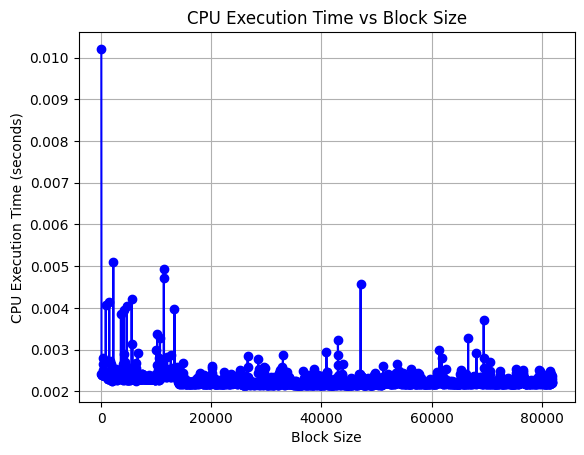

In [30]:
import matplotlib.pyplot as plt

# Read the CPU times data from the file
block_sizes = []
cpu_times = []

with open("cpu_times.txt", "r") as file:
    for line in file:
        block_size, cpu_time = line.strip().split(',')
        block_sizes.append(int(block_size))
        cpu_times.append(float(cpu_time))

# Find the block size with the minimum CPU time
min_cpu_time = min(cpu_times)
best_block_size = block_sizes[cpu_times.index(min_cpu_time)]

# Print the best block size and its corresponding CPU time
print(f"The best block size is {best_block_size} with a CPU execution time of {min_cpu_time:.6f} seconds.")

# Plot the CPU execution time against the block size
plt.plot(block_sizes, cpu_times, marker='o', linestyle='-', color='b')
plt.title('CPU Execution Time vs Block Size')
plt.xlabel('Block Size')
plt.ylabel('CPU Execution Time (seconds)')
plt.grid(True)
plt.show()


# **parallel code from scratch: doesn't work yet**

In [ ]:
%%writefile convolutionV2.cu
#include <opencv2/opencv.hpp>
#include <stdio.h>
#include <math.h>

const int f = 3;
__constant__ int w,h,d_f, resultH, resultW;
__constant__ int d_filtreGXY[2*f*f];



__global__ void filter( unsigned char *imageSource ,  float  *Gradient  )
{

    int tIdx = blockIdx.x*blockDim.x + threadIdx.x ;
    int gradientX=0;
    int gradientY=0;
    int i , imgIdx;
    if(tIdx <resultH*resultW){
        imgIdx = ((tIdx/resultW)+d_f/2)*w + (tIdx%resultW)+d_f/2;


        for (i=-(d_f*d_f)/2 ; i<((d_f*d_f)/2)+1 ; i++)
        {
            gradientX += imageSource[imgIdx+(i/d_f)*w+i%d_f] * d_filtreGXY[i+(d_f*d_f)/2];
            gradientY += imageSource[imgIdx+(i/d_f)*w+i%d_f] * d_filtreGXY[i+(d_f*d_f)/2 + d_f*d_f];
        }
        Gradient[tIdx] = (int)sqrtf(gradientX*gradientX+ gradientY*gradientY);
        Gradient[tIdx] = (Gradient[tIdx]>=255)*255 + (Gradient[tIdx]<255)*Gradient[tIdx];
        }
  }







int main( void )
{

    cv::Mat imageSource = cv::imread("Flower.jpg", cv::IMREAD_GRAYSCALE);
    if (imageSource.empty()) {
        std::cerr << "Error: Could not load image.\n";
        return -1;
    }

    printf("1\n");
    int rows = imageSource.rows;
    int cols = imageSource.cols;
    int resultRows = (rows-f+1);
    int resultCols = (cols-f+1);
    int h_offset = w*(f/2) + f/2;
    size_t size = rows * cols * sizeof(unsigned char);
    printf("%d %d\n", resultRows , resultCols);

    int filtreGXY[6][3] = {
      {-1, 0, 1},
      {-1, 0, 1},
      {-1, 0, 1},
      {-1, -1, -1},
      {0, 0, 0},
      {1, 1, 1}
};
    size_t size_filtre = 2*f*f*sizeof(int);
    size_t size_image_filtree = resultRows*resultCols* sizeof(unsigned char);
    float *imageFiltree;
    cudaMallocManaged(&imageFiltree, size_image_filtree * sizeof(float));
    for (int i = 0; i < resultRows; ++i) {
        for (int j = 0; j < resultCols; ++j) {
            imageFiltree[i * cols + j] = 0; // Set all elements to 0
        }
    }
  cv::imwrite("/content/Flowergray.jpg", imageSource);
    ///#preparing for device
    unsigned char *d_image;
    int *d_filtreGXY;
    cudaMalloc((void**)&d_image, size);
    cudaMalloc((void**)&d_filtreGXY, size_filtre);
    printf("2\n");
    cudaMemcpy(d_image, imageSource.data, size, cudaMemcpyHostToDevice);


    cudaMemcpyToSymbol(w, &cols, sizeof(int));
    cudaMemcpyToSymbol(h, &rows, sizeof(int));
    cudaMemcpyToSymbol(resultH, &resultRows, sizeof(int));
    cudaMemcpyToSymbol(resultW, &resultCols, sizeof(int));
    cudaMemcpyToSymbol(d_filtreGXY, filtreGXY, size_filtre);
    cudaMemcpyToSymbol(d_f, &f, sizeof(int));
    double nbThreads = resultRows*resultCols;
    int threads_per_block = 512;
    int nbBlocks = ceil(nbThreads/threads_per_block);

    filter<<<nbBlocks, threads_per_block>>>(d_image,  imageFiltree);
    cudaDeviceSynchronize();
    //thresholding<<<nbBlocks, threads_per_block>>>(imageFiltree);
    //cudaDeviceSynchronize();
    cudaMemcpy(imageFiltree, imageFiltree, size_image_filtree, cudaMemcpyDeviceToHost);
    cudaFree(d_image);


    cv::Mat filteredImage(resultRows, resultCols, CV_8UC1, imageFiltree);
    cv::imwrite("/content/Filtered_Image2.jpg", filteredImage);

    cudaFree(imageFiltree);
    printf("done");
return 0;
}


In [ ]:
!nvcc -o convolutionV2 convolutionV2.cu `pkg-config --cflags --libs opencv4`

In [ ]:
!./convolutionV2
